# 비동기 라우팅과 스키마

**이 노트북에서 할 일**

1. 실습 폴더의 입력 형식·응답 형식 파일을 읽고, 칸마다 적힌 규칙을 봅니다.
2. 앱 객체에 요청 주소와 처리 함수를 잇고, 서버 프로그램 없이 요청을 넣어 봅니다.
3. 입력 형식이 없는 처리 함수와 있는 처리 함수에 같은 빈 질문을 보내, 몸통까지 가는지 견줍니다.

**준비물** — 이 노트북은 모델을 부르지 않습니다.
모델 요청은 0번이고, API 키 없이 실행합니다.
예상 비용도 0달러입니다.
출력은 모두 앱과 시험용 클라이언트가 주고받은 값이라, 다시 실행해도 같은 값이 나와야 합니다.

요청은 같은 노트북 안에서 앱 객체로 바로 들어갑니다.
서버 프로그램을 따로 띄우지 않아, 네트워크와 포트를 쓰지 않습니다.
읽는 파일은 실습 폴더의 `agent_service/schemas.py` 하나이고, 쓰는 파일은 없습니다.

걸린 시간은 재지 않았습니다.
이 절은 앞 챕터에서 배운 함수를 쓰지 않아, 가져오는 도구 파일도 없습니다.

**기준 버전** — 첫 셀에서 패키지 넷을 설치합니다.
판은 fastapi 0.135.0, httpx 0.28.1, pydantic 2.12.5, starlette 1.6.0입니다.
넷 모두 실습 폴더 잠금과 같은 판입니다.
교재 출력은 Linux의 Python 3.12.13으로 만들었습니다.
다른 판과 Windows·macOS에서는 실행하지 않았습니다.

**강의와 실습 범위** — 강의 시간에는 2~5절을 읽습니다.
요청 주소와 처리 함수를 잇고, 입력 형식이 빈 질문을 멈추는 자리를 Before·After로 보는 자리입니다.
6절은 넣는 값 하나를 바꿔 보는 실습이고, 실습 시간에 실행합니다.

실습 폴더 `labs/part7/ch30-fastapi-serving`에서 `uv sync --locked`를 실행합니다.
그다음 `notebooks/` 폴더의 이 노트북을 열고, 실습 폴더의 `.venv` 커널을 고릅니다.
첫 셀부터 순서대로 실행합니다.

## 오늘 볼 그림

![위에서 아래로 읽는 흐름도입니다. 초록 상자 요청 GET /health에서 파란 상자 앱 객체 demo_app 이어 둔 짝 GET /health로, 다시 파란 상자 처리 함수 health async def를 지나 노란 상자 200 status ok로 화살표가 갑니다. 초록 상자 요청 GET /v1/chat과 POST /health도 앱 객체로 들어가고, 앱 객체에서 점선이 회색 상자 처리 함수를 부르지 않고 라이브러리가 답함으로, 다시 노란 상자 404 Not Found 405 받는 방식 GET으로 이어지는 그림](attachment:01-1-방식과-주소의-짝과-처리-함수.png)

위에서 아래로 읽습니다.
초록 상자는 보낸 요청이고, 파란 상자 둘은 노트북 3절에서 우리가 만든 앱 객체와 처리 함수입니다.
노란 상자는 3절 출력으로 확인한 상태 코드입니다.
점선 갈래의 회색 상자는 처리 함수 없이 라이브러리가 답한 자리입니다.
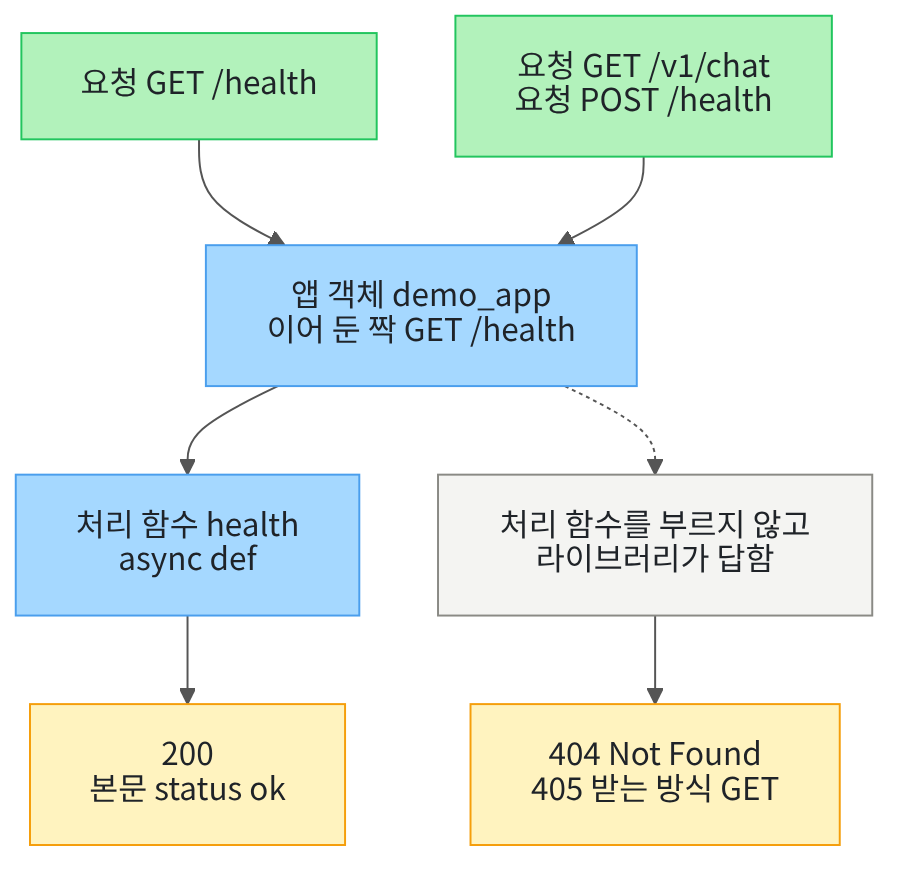

## 1. 준비

이 챕터는 에이전트를 웹 서비스로 내놓습니다.
이 절은 그 첫 단계로, 웹 서비스가 받을 요청과 내놓을 응답의 모양을 정합니다.
제목의 라우팅(routing)은 요청 주소와 처리 함수를 잇는 일입니다.
제목의 스키마(schema)는 요청과 응답의 모양이고, 이 교재에서는 입력 형식과 응답 형식으로 부릅니다.

첫 셀은 패키지 넷을 설치하고 설치된 판 번호를 출력합니다.
설치에는 몇십 초가 걸릴 수 있습니다.

In [1]:
# 이 절에서 쓰는 패키지를 설치하고 버전을 확인합니다
%pip install -q "fastapi==0.135.0" "httpx==0.28.1" "pydantic==2.12.5" "starlette==1.6.0"
from importlib.metadata import version

print("fastapi:", version("fastapi"))
print("httpx:", version("httpx"))
print("pydantic:", version("pydantic"))
print("starlette:", version("starlette"))

Note: you may need to restart the kernel to use updated packages.
fastapi: 0.135.0
httpx: 0.28.1
pydantic: 2.12.5
starlette: 1.6.0


**결과 읽기** — 출력 줄 `fastapi: 0.135.0`과 `pydantic: 2.12.5`가 보입니다.
넷 모두 실습 폴더 잠금과 같은 판입니다.
패키지 fastapi는 파이썬 함수로 웹 서비스를 만드는 라이브러리입니다.
패키지 pydantic은 양식 클래스(`BaseModel`)를 주는 라이브러리입니다.

패키지 starlette는 fastapi가 바탕으로 쓰는 라이브러리이고, 시험용 클라이언트가 이 안에 있습니다.
패키지 httpx는 Ch 4 04절에서 요청을 보낼 때 쓴 라이브러리이고, 시험용 클라이언트가 안에서 씁니다.

다음 셀은 이 절에서 쓸 이름을 가져옵니다.
모듈 `os`·`runpy`는 Python에 들어 있는 모듈입니다.
앱 클래스 `FastAPI`와 시험용 클라이언트 `TestClient`는 패키지 fastapi에서 가져옵니다.

In [2]:
# 이 절에서 쓸 이름을 가져옵니다(os·runpy는 Python에 들어 있는 모듈입니다)
import os
import runpy
from fastapi import FastAPI
from fastapi.testclient import TestClient

print("가져온 fastapi 이름:", "FastAPI, TestClient")

가져온 fastapi 이름: FastAPI, TestClient


**결과 읽기** — 출력 줄 `가져온 fastapi 이름: FastAPI, TestClient`가 보입니다.
이 노트북에는 API 키를 확인하는 셀이 없습니다.
모델을 부르지 않기 때문입니다.

## 2. 실습 폴더의 입력 형식 읽기

이 챕터의 앱 코드는 실습 폴더 맨 위의 폴더 `agent_service/`에 있습니다.
이 절은 그 가운데 입력 형식·응답 형식을 적은 파일 `schemas.py`만 읽습니다.
노트북을 어디서 열었는지에 따라 이 파일을 가리키는 글이 달라집니다.
다음 셀은 Ch 28 01절의 파일 위치 셀처럼 후보 셋을 차례로 보고, 처음 있는 것을 고릅니다.

In [3]:
# 노트북을 연 자리에서 본 실습 폴더의 위치를 후보 셋 가운데에서 고릅니다
candidates = ["..", ".", "labs/part7/ch30-fastapi-serving"]
lab_path = None
for candidate in candidates:
    if os.path.exists(candidate + "/agent_service/schemas.py"):
        lab_path = candidate
        break
print("실습 폴더를 찾았는가:", lab_path is not None)
assert lab_path is not None, "notebooks 폴더나 실습 폴더 맨 위에서 노트북을 열어 주세요."

실습 폴더를 찾았는가: True


**결과 읽기** — 출력 줄 `실습 폴더를 찾았는가: True`가 보입니다.
첫 후보 `..`는 `notebooks/` 폴더에서 열었을 때 맞는 자리입니다.
둘째 `.`는 실습 폴더 맨 위, 셋째는 프로젝트 맨 위에서 열었을 때 맞습니다.
학생 묶음을 풀어 `notebooks/`에서 열어도 첫 후보가 맞습니다.
고른 후보는 연 자리마다 달라서 출력하지 않습니다.

다음 셀은 Ch 28 01절처럼 함수 `runpy.run_path`로 이 파일을 실행합니다.
그 파일이 만든 이름을 딕셔너리로 받고, 양식 클래스 둘을 꺼냅니다.
파일 `schemas.py`는 pydantic만 가져오는 파일이라, 이 함수로 읽을 수 있습니다.

In [4]:
# 실습 폴더의 형식 파일을 실행해, 그 파일이 만든 이름을 딕셔너리로 받습니다
schema_names = runpy.run_path(lab_path + "/agent_service/schemas.py")
ChatRequest = schema_names["ChatRequest"]
ChatResponse = schema_names["ChatResponse"]
print("입력 형식 클래스:", ChatRequest.__name__)
print("응답 형식 클래스:", ChatResponse.__name__)

입력 형식 클래스: ChatRequest
응답 형식 클래스: ChatResponse


**결과 읽기** — 출력 줄 `입력 형식 클래스: ChatRequest`와 `응답 형식 클래스: ChatResponse`가 보입니다.
두 클래스 모두 Ch 6 03절의 양식 클래스(`BaseModel`)입니다.
입력 형식은 요청 본문에 올 칸을, 응답 형식은 응답 본문에 내보낼 칸을 정합니다.
이 절에서는 노트북에서 양식 클래스를 새로 만들지 않고, 실습 폴더의 두 클래스를 씁니다.

다음 셀은 입력 형식에 적힌 규칙을 봅니다.
메서드 `model_json_schema`는 Ch 6 03절에서 쓴 메서드로, 양식 클래스를 딕셔너리로 바꿉니다.
키 `required`에는 꼭 있어야 하는 칸이, 키 `properties`에는 칸마다의 규칙이 들어 있습니다.

In [5]:
# 입력 형식을 딕셔너리로 바꿔, 꼭 있어야 하는 칸과 칸마다 적힌 규칙을 봅니다
request_format = ChatRequest.model_json_schema()
print("꼭 있어야 하는 칸:", request_format["required"])
print("칸 question의 규칙:", request_format["properties"]["question"])
print("칸 thread_id의 규칙:", request_format["properties"]["thread_id"])

꼭 있어야 하는 칸: ['question', 'thread_id']
칸 question의 규칙: {'examples': ['휴관일을 알려 주세요'], 'maxLength': 500, 'minLength': 1, 'title': 'Question', 'type': 'string'}
칸 thread_id의 규칙: {'examples': ['demo-01'], 'pattern': '^[a-zA-Z0-9_-]{1,64}$', 'title': 'Thread Id', 'type': 'string'}


**결과 읽기** — 출력 줄 `꼭 있어야 하는 칸: ['question', 'thread_id']`가 보입니다.
칸 question의 규칙에 `'maxLength': 500`과 `'minLength': 1`이 있습니다.
질문은 한 글자 이상, 500글자 이하인 글이어야 한다는 뜻입니다.
칸 thread_id의 규칙 `'pattern'`은 받을 글의 모양을 정한 정규식(Ch 16 02절)입니다.

정규식은 영문자·숫자·밑줄·줄표로 된 한 글자부터 64글자까지의 글만 받습니다.
칸 `thread_id`는 Ch 23 01절처럼 대화 하나를 가르는 이름을 적는 자리입니다.
칸 `examples`는 문서에 보일 예시 글이고, 검사에는 쓰지 않습니다.

다음 셀은 응답 형식도 같은 메서드로 봅니다.

In [6]:
# 응답 형식도 딕셔너리로 바꿔, 칸 이름과 꼭 있어야 하는 칸을 봅니다
response_format = ChatResponse.model_json_schema()
print("응답 형식의 칸:", list(response_format["properties"]))
print("꼭 있어야 하는 칸:", response_format["required"])

응답 형식의 칸: ['answer', 'thread_id']
꼭 있어야 하는 칸: ['answer', 'thread_id']


**결과 읽기** — 출력 줄 `응답 형식의 칸: ['answer', 'thread_id']`가 보입니다.
두 칸 모두 꼭 있어야 하는 칸입니다.
이 앱이 응답 본문으로 내보낼 칸은 답 글과 대화 이름, 이 둘뿐이라는 약속입니다.

## 3. 요청 주소와 처리 함수 잇기

앱 클래스 `FastAPI`로 만든 앱 객체는 요청 방식과 요청 주소의 짝마다 부를 함수를 기억합니다.
요청 방식(method)은 GET·POST처럼 요청이 무엇을 하려는지 적은 말이고, Ch 4 04절에서 GET을 썼습니다.
요청 주소는 Ch 15 08절의 말로, 요청을 받을 기능의 주소입니다.
다음 셀은 연습용 앱 객체를 하나 만듭니다.

In [7]:
# 요청 방식·요청 주소의 짝과 처리 함수를 이어 둘 앱 객체를 하나 만듭니다
demo_app = FastAPI(title="연습 앱")
print("앱 이름:", demo_app.title)

앱 이름: 연습 앱


**결과 읽기** — 출력 줄 `앱 이름: 연습 앱`이 보입니다.
인자 `title`은 앱의 이름이고, 앱 문서에 쓰입니다.

다음 셀은 요청 방식 GET과 요청 주소 `/health`의 짝을 함수 하나에 잇습니다.
함수 위의 줄 `@demo_app.get("/health")`는 데코레이터 줄입니다.
이 줄은 아래 함수를 앱 객체에 넘겨, GET `/health` 요청이 오면 부를 함수로 등록합니다.
데코레이터의 뜻은 Ch 2 09절에 있고, Ch 28 02절에서 도구를 붙일 때도 같은 모양을 썼습니다.
이렇게 등록한 함수를 이 챕터에서는 처리 함수라고 부릅니다.

정의 줄의 `async def`는 Ch 2 12절의 비동기 함수입니다.
요청이 오면 라이브러리가 이 함수를 불러 만든 코루틴을 await로 기다립니다.
함수가 내놓은 딕셔너리는 JSON 글로 바뀌어 응답 본문이 됩니다.

In [8]:
# 요청 방식 GET과 요청 주소 /health의 짝을 아래 처리 함수에 잇습니다
@demo_app.get("/health")
async def health():
    return {"status": "ok"}

**결과 읽기** — 정의 셀이라 출력이 없습니다.
요청이 와야 이 함수가 불립니다.

다음 셀은 시험용 클라이언트로 이 앱에 요청을 넣습니다.
클래스 `TestClient`는 앱 객체를 받아, 서버 프로그램 없이 같은 노트북 안에서 앱에 요청을 넣습니다.
메서드 `get`은 GET 요청을 보내고, 응답은 Ch 4 04절의 httpx 응답과 같은 모양입니다.
상태 코드는 속성 `status_code`로, 본문은 메서드 `json()`으로 읽습니다.

In [9]:
# 시험용 클라이언트로 앱에 GET /health 요청을 넣고, 상태 코드와 본문을 봅니다
demo_client = TestClient(demo_app)
health_response = demo_client.get("/health")
print("상태 코드:", health_response.status_code)
print("본문:", health_response.json())

상태 코드: 200
본문: {'status': 'ok'}


**결과 읽기** — 출력 줄 `상태 코드: 200`과 `본문: {'status': 'ok'}`가 보입니다.
처리 함수 `health`가 내놓은 딕셔너리가 그대로 응답 본문이 되었습니다.

시험용 클라이언트는 httpx의 클라이언트를 바탕으로 만든 클래스입니다.
그래서 요청을 보내는 메서드와 응답을 읽는 방법이 httpx와 같습니다.

다음 셀은 이어 둔 적 없는 짝 두 가지를 보냅니다.
하나는 이어 두지 않은 요청 주소 `/v1/chat`에 보내는 GET 요청입니다.
다른 하나는 이어 둔 요청 주소 `/health`에 방식만 POST로 바꾼 요청입니다.
응답 머리(헤더)는 본문과 따로 오는 이름과 값의 목록이고, 그 가운데 칸 `allow`도 봅니다.

In [10]:
# 이어 둔 적 없는 요청 주소와, 이어 둔 요청 주소에 다른 요청 방식을 보내 봅니다
missing_response = demo_client.get("/v1/chat")
wrong_method_response = demo_client.post("/health")
print("없는 요청 주소:", missing_response.status_code, missing_response.json())
print("다른 요청 방식:", wrong_method_response.status_code, wrong_method_response.json())
# 응답 머리(헤더)의 칸 allow는 그 요청 주소가 받는 요청 방식입니다
print("받는 요청 방식:", wrong_method_response.headers["allow"])

없는 요청 주소: 404 {'detail': 'Not Found'}
다른 요청 방식: 405 {'detail': 'Method Not Allowed'}
받는 요청 방식: GET


**결과 읽기** — 출력 줄 `없는 요청 주소: 404 {'detail': 'Not Found'}`가 보입니다.
상태 코드 `404`는 Ch 4 04절에서 본 「찾을 수 없음」입니다.
방식만 바꾼 요청은 `405`와 `Method Not Allowed`를 받았고, 받는 요청 방식은 `GET`이었습니다.
두 응답 모두 처리 함수를 부르지 않고 라이브러리가 만든 응답입니다.
앱 객체는 요청 주소만이 아니라, 방식과 주소의 짝으로 처리 함수를 고릅니다.

이 챕터의 앱은 처리 함수 안에서 에이전트 그래프를 부릅니다.
이 절에서는 그 자리에 모델을 부르지 않는 평범한 함수를 둡니다.
다음 셀의 함수 `make_result`는 질문을 받아, 답과 메시지 목록을 담은 결과 딕셔너리를 내놓습니다.
키 둘(`messages`·`answer`)은 실습 폴더 `agent_service/agent.py`의 상태 형식에 적힌 칸 이름과 같습니다.

In [11]:
# 질문 하나로 결과 딕셔너리를 만듭니다(모델을 부르지 않는 평범한 동기 함수입니다)
def make_result(question):
    answer = "질문을 확인했습니다: " + question
    result = {"messages": [question], "answer": answer}
    return result

**결과 읽기** — 정의 셀이라 출력이 없습니다.
정의 줄에 `async`가 없는 동기 함수입니다.
답 글은 앞말 「질문을 확인했습니다: 」 뒤에 질문을 그대로 이은 글입니다.

다음 셀은 이 함수를 처리 함수에 넣기 전에 바로 불러 봅니다.

In [12]:
# 처리 함수에 넣기 전에, 함수를 바로 불러 결과 딕셔너리의 모양을 봅니다
sample_result = make_result("휴관일을 알려 주세요")
print("결과 딕셔너리의 키:", list(sample_result))
print("답:", sample_result["answer"])

결과 딕셔너리의 키: ['messages', 'answer']
답: 질문을 확인했습니다: 휴관일을 알려 주세요


**결과 읽기** — 출력 줄 `결과 딕셔너리의 키: ['messages', 'answer']`가 보입니다.
답은 `질문을 확인했습니다: 휴관일을 알려 주세요`입니다.
이 결과에는 응답 형식에 없는 키 `messages`가 들어 있습니다.

이 함수는 처리 함수 안에서 부를 동기 함수입니다.
글을 잇기만 해서 금방 끝나므로, 처리 함수가 이 줄에서 오래 멈추지 않습니다.
Ch 2 12절의 차단 호출처럼 오래 기다리는 동기 호출이라면 이야기가 다릅니다.
그동안 이벤트 루프가 멈춰, 같은 앱에 온 다른 요청의 처리 함수도 시작하지 못합니다.
이 장면은 노트북 밖에서 확인했고, 본문 「주의할 점」에 적었습니다.

## 4. 입력 형식 없이 받는 처리 함수 (Before)

이제 질문을 받는 요청 주소 `/v1/chat`을 만듭니다.
Before 앱의 처리 함수는 요청 본문을 딕셔너리로 받고, 응답 형식도 적지 않습니다.
다음 셀은 Before 앱과, 몸통에 들어온 질문을 적어 둘 빈 목록 `body_inputs`를 만듭니다.
Ch 28 02절에서 도구 몸통에 들어온 값을 목록에 적은 방법과 같습니다.

In [13]:
# Before: 입력 형식·응답 형식을 적지 않을 앱과, 몸통에 들어온 질문을 적어 둘 빈 목록을 만듭니다
before_app = FastAPI(title="형식 없는 앱")
body_inputs = []
print("앱 이름:", before_app.title)

앱 이름: 형식 없는 앱


**결과 읽기** — 출력 줄 `앱 이름: 형식 없는 앱`이 보입니다.
목록 `body_inputs`는 요청을 보내는 셀마다 첫 줄에서 새 빈 목록으로 바꿉니다.

다음 셀은 처리 함수를 POST `/v1/chat`에 잇습니다.
라이브러리는 처리 함수의 매개변수 힌트를 보고, 요청의 어느 부분을 어떻게 읽을지 정합니다.
힌트 `dict`는 JSON 객체라면 무엇이든 요청 본문으로 받는다는 뜻이고, 칸마다의 규칙이 없습니다.
그래서 이 챕터는 처리 함수의 매개변수에 힌트를 적습니다.
Ch 28 02절에서 도구 매개변수 힌트가 입력 형식이 된 것과 같은 까닭입니다.

In [14]:
# 요청 본문을 딕셔너리로 받는 처리 함수를 POST /v1/chat에 잇습니다
@before_app.post("/v1/chat")
async def chat_before(body: dict):
    question = body["question"]
    # 몸통에 들어온 질문을 적어 둡니다(몸통까지 왔는지 보려는 줄입니다)
    body_inputs.append(question)
    result = make_result(question)
    result["thread_id"] = body["thread_id"]
    return result

**결과 읽기** — 정의 셀이라 출력이 없습니다.
처리 함수는 본문 딕셔너리에서 칸 `question`과 `thread_id`를 꺼내 씁니다.
결과 딕셔너리에 `thread_id`를 더해 그대로 내놓습니다.

다음 셀은 맞는 질문 「휴관일을 알려 주세요」를 보냅니다.
메서드 `post`의 인자 `json`에 딕셔너리를 넘기면, 시험용 클라이언트가 JSON 글로 바꿔 요청 본문에 싣습니다.
요청 방식 POST는 본문에 값을 실어 보내는 방식입니다.

In [15]:
# 맞는 질문을 보내고, 상태 코드·응답 본문의 키·몸통에 들어온 값을 봅니다
before_client = TestClient(before_app)
body_inputs = []
normal_request = {"question": "휴관일을 알려 주세요", "thread_id": "demo-01"}
before_ok = before_client.post("/v1/chat", json=normal_request)
before_ok_body = before_ok.json()
print("상태 코드:", before_ok.status_code)
print("응답 본문의 키:", list(before_ok_body))
print("몸통에 들어온 값:", body_inputs)

상태 코드: 200
응답 본문의 키: ['messages', 'answer', 'thread_id']
몸통에 들어온 값: ['휴관일을 알려 주세요']


**결과 읽기** — 출력 줄 `상태 코드: 200`과 `몸통에 들어온 값: ['휴관일을 알려 주세요']`가 보입니다.
라벨 `응답 본문의 키:` 뒤에는 `'messages'`까지 키 셋이 있습니다.
처리 함수가 만든 결과 딕셔너리가 거르지 않고 그대로 밖으로 나갔습니다.
키 `messages`는 앱 안쪽에서 쓰는 값이라, 받는 쪽이 이 칸에 기대면 앱을 고치기 어려워집니다.

다음 셀은 칸 `question`만 빈 글로 바꿔 보냅니다.
실행 전에 예상해 봅니다.
빈 질문도 몸통까지 들어갈까요?

In [16]:
# 칸 question만 빈 글로 바꿔 보내고, 상태 코드·응답 본문·몸통에 들어온 값을 봅니다
body_inputs = []
empty_request = {"question": "", "thread_id": "demo-01"}
before_empty = before_client.post("/v1/chat", json=empty_request)
print("상태 코드:", before_empty.status_code)
print("응답 본문:", before_empty.json())
print("몸통에 들어온 값:", body_inputs)

상태 코드: 200
응답 본문: {'messages': [''], 'answer': '질문을 확인했습니다: ', 'thread_id': 'demo-01'}
몸통에 들어온 값: ['']


**결과 읽기** — 출력 줄 `상태 코드: 200`과 `몸통에 들어온 값: ['']`가 보입니다.
빈 질문이 몸통까지 들어가 결과 딕셔너리를 만들었고, 답은 앞말만 남은 `'질문을 확인했습니다: '`입니다.
받는 쪽은 상태 코드 200만 보고, 요청이 잘 처리됐다고 여깁니다.
이것이 이 절의 Before 결함입니다.

몸통에서 에이전트를 불렀다면, 빈 질문으로 모델 요청이 나갔을 자리입니다.
이 절은 모델을 부르지 않지만, 몸통의 모든 줄이 빈 질문으로 실행됐습니다.

## 5. 입력 형식을 적은 처리 함수 (After)

After 앱은 몸통을 그대로 두고 두 가지만 바꿉니다.
매개변수 힌트를 입력 형식 `ChatRequest`로 적고, 데코레이터 줄에 응답 형식을 적습니다.
힌트가 양식 클래스이면 라이브러리는 요청 본문 JSON을 그 양식으로 검사한 뒤 처리 함수를 부릅니다.
검사에 걸리면 처리 함수를 부르지 않고, 상태 코드 422로 답합니다.
다음 셀은 After 앱을 만듭니다.

In [17]:
# After: 실습 폴더의 입력 형식·응답 형식을 쓸 앱을 만듭니다
after_app = FastAPI(title="형식 있는 앱")
print("앱 이름:", after_app.title)

앱 이름: 형식 있는 앱


**결과 읽기** — 출력 줄 `앱 이름: 형식 있는 앱`이 보입니다.

다음 셀은 After 처리 함수를 같은 요청 주소 `/v1/chat`에 잇습니다.
데코레이터 줄의 인자 `response_model`에 응답 형식 `ChatResponse`를 넘깁니다.
몸통에서 칸을 꺼내는 모양만 `body["question"]`에서 속성 `body.question`으로 바뀝니다.
매개변수 `body`에 딕셔너리 대신 입력 형식의 객체가 들어오기 때문입니다.

In [18]:
# 몸통은 그대로 두고, 요청 본문을 입력 형식으로 받고 응답 형식으로 내보내는 처리 함수를 잇습니다
@after_app.post("/v1/chat", response_model=ChatResponse)
async def chat_after(body: ChatRequest):
    question = body.question
    # 몸통에 들어온 질문을 적어 둡니다(Before와 같은 줄입니다)
    body_inputs.append(question)
    result = make_result(question)
    result["thread_id"] = body.thread_id
    return result

**결과 읽기** — 정의 셀이라 출력이 없습니다.
몸통은 Before처럼 결과 딕셔너리를 내놓습니다.
응답 형식이 그 가운데 칸 둘만 골라 보냅니다.

다음 셀은 Before와 같은 맞는 질문을 보냅니다.

In [19]:
# Before와 같은 맞는 질문을 보내고, 상태 코드·응답 본문·몸통에 들어온 값을 봅니다
after_client = TestClient(after_app)
body_inputs = []
after_ok = after_client.post("/v1/chat", json=normal_request)
after_ok_body = after_ok.json()
print("상태 코드:", after_ok.status_code)
print("응답 본문:", after_ok_body)
print("답이 Before와 같은가:", after_ok_body["answer"] == before_ok_body["answer"])
print("몸통에 들어온 값:", body_inputs)

상태 코드: 200
응답 본문: {'answer': '질문을 확인했습니다: 휴관일을 알려 주세요', 'thread_id': 'demo-01'}
답이 Before와 같은가: True
몸통에 들어온 값: ['휴관일을 알려 주세요']


**결과 읽기** — 출력 줄 `상태 코드: 200`과 `답이 Before와 같은가: True`가 보입니다.
응답 본문에는 `'answer'`와 `'thread_id'` 두 칸만 있고, 키 `messages`는 빠졌습니다.
몸통은 결과 딕셔너리를 그대로 내놓았지만, 응답 형식에 없는 칸을 라이브러리가 걸러 냈습니다.

다음 셀은 Before와 같은 빈 질문을 보냅니다.
이번에도 빈 질문이 몸통까지 들어갈까요?

In [20]:
# Before와 같은 빈 질문을 보내고, 상태 코드와 몸통에 들어온 값을 봅니다
body_inputs = []
after_empty = after_client.post("/v1/chat", json=empty_request)
print("상태 코드:", after_empty.status_code)
print("몸통에 들어온 값:", body_inputs)

상태 코드: 422
몸통에 들어온 값: []


**결과 읽기** — 출력 줄 `상태 코드: 422`와 `몸통에 들어온 값: []`가 보입니다.
입력 형식의 규칙 「한 글자 이상」에 걸려, 처리 함수가 불리지 않았습니다.
받는 쪽은 상태 코드만 보고도 요청이 잘못됐다는 것을 압니다.

상태 코드 422는 요청 본문이 입력 형식에 맞지 않을 때 라이브러리가 내는 값입니다.
다음 셀은 422 응답 본문의 목록 `detail`에서 첫 항목을 봅니다.

In [21]:
# 422 응답 본문의 목록 detail에서 첫 항목을 꺼내, 칸 이름과 칸마다의 값을 봅니다
first_error = after_empty.json()["detail"][0]
print("항목의 칸:", list(first_error))
print("오류 종류:", first_error["type"])
print("걸린 자리:", first_error["loc"])
print("안내 글:", first_error["msg"])
print("어긴 규칙:", first_error["ctx"])

항목의 칸: ['type', 'loc', 'msg', 'input', 'ctx']
오류 종류: string_too_short
걸린 자리: ['body', 'question']
안내 글: String should have at least 1 character
어긴 규칙: {'min_length': 1}


**결과 읽기** — 출력 줄 `오류 종류: string_too_short`와 `걸린 자리: ['body', 'question']`이 보입니다.
요청 본문(`body`)의 칸 `question`이 너무 짧다는 뜻입니다.
칸 `ctx`에는 어긴 규칙 `{'min_length': 1}`이 담겼습니다.
받는 쪽은 이 칸들을 읽어, 사람이 고칠 자리를 알려 줄 수 있습니다.

라벨 `항목의 칸:` 뒤에는 칸 `input`도 있습니다.
넣은 값이 그대로 담기는 칸이라, 받는 쪽 화면에 그대로 띄우지 않는 편이 안전합니다.

## 6. 값 바꿔 보기: 공백 한 칸

값 하나만 바꿔 봅니다.
바꿀 값은 칸 `question`이고, 공백 한 칸 `" "`을 넣습니다.
같은 요청을 Before와 After 앱에 차례로 보냅니다.
실행 전에 예상해 봅니다.
After 앱의 입력 형식은 공백 한 칸을 막을까요?

In [22]:
# 칸 question만 공백 한 칸으로 바꿔, Before와 After 앱에 차례로 보냅니다
body_inputs = []
space_request = {"question": " ", "thread_id": "demo-01"}
before_space = before_client.post("/v1/chat", json=space_request)
after_space = after_client.post("/v1/chat", json=space_request)
print("Before 상태 코드:", before_space.status_code)
print("After 상태 코드:", after_space.status_code)
print("몸통에 들어온 값:", body_inputs)

Before 상태 코드: 200
After 상태 코드: 200
몸통에 들어온 값: [' ', ' ']


**결과 읽기** — 출력 줄 `After 상태 코드: 200`과 `몸통에 들어온 값: [' ', ' ']`가 보입니다.
공백 한 칸도 한 글자라서, 규칙 「한 글자 이상」을 지났습니다.
입력 형식은 적어 둔 규칙만 검사하고, 글에 뜻이 있는지는 보지 않습니다.

공백만 있는 질문까지 막으려면 규칙을 더 적거나, 몸통에서 따로 검사해야 합니다.
이 절에서는 그 방법을 실행하지 않았습니다.

## 정리

1. 앱 객체는 요청 방식과 요청 주소의 짝으로 처리 함수를 골랐고, 이어 두지 않은 짝에는 404·405로 답했습니다.
2. 입력 형식이 없는 처리 함수는 빈 질문도 몸통까지 들여 200으로 답했고, 앱 안쪽 키 messages까지 내보냈습니다.
3. 입력 형식을 적자 빈 질문은 몸통 전에 422로 멈췄고, 응답 형식이 칸 둘만 골라 보냈습니다.

02절에서는 처리 함수가 쓸 객체를 라이브러리가 넘겨 주게 하고, 시험 때 그 객체를 바꿔 끼우는 방법을 봅니다.